# 🦴 PENGWIN — notebook de control del pipeline

Este notebook **no contiene el código del modelo**: llama a los scripts de `scripts/` y a las
funciones de `src/`. El código vive en un solo lugar (el que se revisa en los Pull Requests)
y el notebook solo orquesta, muestra resultados y deja las gráficas para el informe.

> Si algo necesita cambiarse, se cambia en `src/` o en `configs/`, **no aquí**. Así el notebook
> nunca queda desincronizado con lo que se entrega.

**Cómo usarlo**
1. Ajusta la celda de **Parámetros**. Por defecto trabaja con los datos reales, no rehace la caché
   ni entrena: sirve para ver resultados, evaluar y visualizar sin tocar lo que ya existe.
   `MODO_PRUEBA = True` solo para comprobar una instalación nueva; escribe en carpetas aparte.
2. Corre las secciones en orden. Cada sección corresponde a una semana del cronograma.
3. Los entrenamientos largos se lanzan desde la terminal (sección 4).

| Sección | Semana | Qué hace |
|---|---|---|
| 0 | — | entorno, GPU, configuración |
| 1 | 8 | datos: caché + splits por paciente |
| 2 | 8 | EDA + visualizador 1 (MIP raw) |
| 3 | 9 | memoria, overfit test, calibración de λ |
| 4 | 9–10 | entrenamiento por etapas |
| 5 | 10 | evaluación (métricas sección 5 + robustez) |
| 6 | 10–11 | inferencia + visualizadores 2 y 3 sobre un paciente con fractura |
| 7 | 10–11 | interpretabilidad: γ de BatchNorm, Grad-CAM, cajas y NMS, galería de fracturas |
| 8 | 10 | baseline SAM |
| 9 | 11 | dashboard + túnel de Cloudflare |

⚠️ **Uso exclusivamente académico.** No es un dispositivo médico ni está validado clínicamente.

## 0 · Parámetros y entorno

In [1]:
# ============================ PARAMETROS ============================
MODO_PRUEBA   = False       
NOMBRE_EXP    = "sin_cbam_384"  # carpeta de checkpoints/resultados: "completo", "sin_cbam", "con_tl"
CONFIG_BASE   = "configs/ablacion_sin_cbam_384.yaml"  # ablaciones: configs/ablacion_sin_cbam.yaml, configs/ablacion_con_tl.yaml
DEVICE        = None        # None = GPU si hay, si no CPU

REHACER_DATOS = False       # True solo para reconstruir cache, splits y EDA
ENTRENAR      = False       # los entrenamientos largos se corren desde la terminal
CORRER_PRUEBAS = False      # perfil de memoria, overfit test y calibracion de lambdas (seccion 3)
EVALUAR       = False       # evaluacion completa sobre test (seccion 5), usa la GPU varios minutos

# Rutas del dataset real (solo si MODO_PRUEBA = False).
# Las imagenes de part1.zip y part2.zip van en la MISMA carpeta.
RUTA_IMAGENES  = "data/raw/images"
RUTA_ETIQUETAS = "data/raw/labels"

# Colab: carpeta de Google Drive donde subieron los 3 zip de Zenodo
DRIVE_ZIPS = "/content/drive/MyDrive/PENGWIN"
# ====================================================================

In [2]:
import os, sys, subprocess, json, shutil
from pathlib import Path

ENTORNO = "colab" if "google.colab" in sys.modules else ("kaggle" if Path("/kaggle").exists() else "local")
REPO_URL = "https://github.com/ShadowBlack33/Proyecto-2-Analitica-de-Datos.git"

if ENTORNO == "local":
    # el notebook vive en notebooks/: se trabaja desde la raiz del repo
    if Path.cwd().name == "notebooks":
        os.chdir("..")
else:
    base = Path("/content") if ENTORNO == "colab" else Path("/kaggle/working")
    repo = base / "Proyecto-2-Analitica-de-Datos"
    if not repo.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(repo)], check=True)
    os.chdir(repo)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "SimpleITK", "streamlit", "medpy"], check=False)

RAIZ = Path.cwd()
assert (RAIZ / "src").exists() and (RAIZ / "configs").exists(), f"No estoy en la raiz del repo: {RAIZ}"
sys.path.insert(0, str(RAIZ))
print("entorno:", ENTORNO, "| raiz:", RAIZ)

entorno: local | raiz: c:\Users\Carlo\Downloads\Analitica\Proyecto-2-Analitica\pengwin-repo-organizado


In [3]:
def correr(*args, guardar=None):
    """Corre un script con EL MISMO Python de este kernel (sys.executable).
    En Windows, `!python` puede usar otro Python distinto al del venv del kernel;
    esto lo evita. Muestra la salida en vivo y se detiene si el script falla."""
    cmd = [sys.executable, *[str(a) for a in args]]
    print("$", " ".join(cmd[1:]))
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                         encoding="utf-8", errors="replace", cwd=RAIZ)
    salida = []
    for linea in p.stdout:
        print(linea, end="")
        salida.append(linea)
    if guardar:
        Path(guardar).parent.mkdir(parents=True, exist_ok=True)
        Path(guardar).write_text("".join(salida), encoding="utf-8")
    if p.wait() != 0:
        raise RuntimeError(f"fallo: {' '.join(cmd[1:])}")

import torch
print("PyTorch", torch.__version__)
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} · {p.total_memory / 1024**3:.1f} GB")
else:
    print("Sin GPU: todo corre en CPU (lento para entrenar, suficiente para probar)")

PyTorch 2.6.0+cu124
GPU: NVIDIA GeForce RTX 3060 Laptop GPU · 6.0 GB


### Configuración del experimento
Se parte de `configs/default.yaml` y se escribe `configs/notebook.yaml` con las rutas de este
entorno. `default.yaml` no se toca desde aquí: es la configuración oficial que cita el informe.

In [4]:
import yaml
from src.utils import cargar_config

cfg = cargar_config(CONFIG_BASE)

if MODO_PRUEBA:
    cfg["rutas"]["imagenes"]  = "data/sintetico/images"
    cfg["rutas"]["etiquetas"] = "data/sintetico/labels"
    cfg["rutas"]["cache"]     = "data/cache_sintetico"
    cfg["rutas"]["splits"]    = "data/splits_sintetico.json"
    cfg["rutas"]["checkpoints"] = "checkpoints/prueba_sintetica"
    cfg["rutas"]["resultados"]  = "resultados/prueba_sintetica"
    ENTRENAR, EVALUAR, CORRER_PRUEBAS = True, True, True
    # prueba rapida: resolucion baja y pocas epocas
    cfg["datos"]["resolucion"] = 128
    cfg["entrenamiento"]["batch_size"] = 4
    for etapa, ep in zip(cfg["entrenamiento"]["etapas"], [3, 3, 1, 1]):
        etapa["epocas"] = ep
else:
    cfg["rutas"]["imagenes"]  = RUTA_IMAGENES
    cfg["rutas"]["etiquetas"] = RUTA_ETIQUETAS

CONFIG = "configs/notebook.yaml"
with open(CONFIG, "w", encoding="utf-8") as f:
    yaml.safe_dump(cfg, f, sort_keys=False, allow_unicode=True)

RES = Path(cfg["rutas"]["resultados"])
CKPT_DIR = Path(cfg["rutas"]["checkpoints"]) / NOMBRE_EXP
print("config:", CONFIG, "| imagenes:", cfg["rutas"]["imagenes"])

config: configs/notebook.yaml | imagenes: data/raw/images


## 1 · Datos (semana 8)

**Solo Colab:** copia los zip desde Drive y los descomprime en el disco local de la sesión
(descomprimir directo desde Drive es muy lento). Tarda unos minutos; solo hace falta una vez por sesión.
En local, descomprime los zip a mano en `data/raw/images` y `data/raw/labels`.

In [5]:
if ENTORNO == "colab" and not MODO_PRUEBA:
    from google.colab import drive
    drive.mount("/content/drive")
    import zipfile
    destino = {"PENGWIN_CT_train_images_part1.zip": RUTA_IMAGENES,
               "PENGWIN_CT_train_images_part2.zip": RUTA_IMAGENES,
               "PENGWIN_CT_train_labels.zip": RUTA_ETIQUETAS}
    for nombre, carpeta in destino.items():
        Path(carpeta).mkdir(parents=True, exist_ok=True)
        print("descomprimiendo", nombre)
        with zipfile.ZipFile(Path(DRIVE_ZIPS) / nombre) as z:
            for m in z.infolist():
                if m.is_dir():
                    continue
                m.filename = Path(m.filename).name   # aplana subcarpetas del zip
                z.extract(m, carpeta)
else:
    print("(se omite: no es Colab o estamos en MODO_PRUEBA)")

(se omite: no es Colab o estamos en MODO_PRUEBA)


In [6]:
if MODO_PRUEBA:
    correr("scripts/generar_datos_sinteticos.py", "--n", 8, "--salida", "data/sintetico")

n_img = len(list(Path(cfg["rutas"]["imagenes"]).glob("*.mha")))
n_lbl = len(list(Path(cfg["rutas"]["etiquetas"]).glob("*.mha")))
print(f"{n_img} imagenes | {n_lbl} etiquetas")
assert n_img > 0, "No hay volumenes: revisa las rutas de la celda de parametros"

100 imagenes | 100 etiquetas


Caché de cortes 256×256 + splits **por paciente** (nunca por corte) con su hash SHA-256.
Con el dataset real tarda del orden de minutos por lote de casos; se hace una sola vez.

In [7]:
cache = Path(cfg["rutas"]["cache"])
listos = Path(cfg["rutas"]["splits"]).exists() and cache.exists() and any(cache.iterdir())
if REHACER_DATOS or not listos:
    correr("scripts/preparar_datos.py", "--config", CONFIG)
else:
    print("Datos ya preparados: se usa la cache existente (REHACER_DATOS = True para reconstruirla)")

splits = json.load(open(cfg["rutas"]["splits"]))
print({k: len(v) for k, v in splits["splits"].items()}, "| sha256", splits["sha256"][:16])

Datos ya preparados: se usa la cache existente (REHACER_DATOS = True para reconstruirla)
{'train': 70, 'val': 15, 'test': 15} | sha256 99267ddb2310271e


## 2 · EDA + visualizador 1 (semana 8)

In [8]:
if REHACER_DATOS or not (RES / "eda" / "eda_casos.csv").exists():
    correr("scripts/eda.py", "--config", CONFIG)
else:
    print("EDA ya calculado: se muestran los resultados guardados (REHACER_DATOS = True para recalcular)")

EDA ya calculado: se muestran los resultados guardados (REHACER_DATOS = True para recalcular)


,id,Z,H,W,spacing_z_mm,spacing_y_mm,spacing_x_mm,hu_min,hu_max,nitidez_lap,ruido_aire_hu,espesor_corte_mm,pixel_mm,n_frag_SA,n_frag_LI,n_frag_RI
0,1,401,512,512,0.8,0.781250,0.781250,-1023,2775,0.162197,24.359830,0.8,0.781250,1,2,1
1,2,337,276,413,0.8,0.824219,0.824219,-1023,4711,0.019566,22.871364,0.8,0.824219,2,1,3
2,3,285,381,512,1.0,0.759766,0.759766,-1023,16709,0.018498,23.433941,1.0,0.759766,1,4,1
3,4,224,254,386,1.0,0.843750,0.843750,-1418,4961,0.025360,23.242065,1.0,0.843750,2,2,2
4,5,312,512,512,1.0,0.896484,0.896484,-1023,4695,0.054580,17.802507,1.0,0.896484,1,2,3


,count,mean,std,min,25%,50%,75%,max
id,100.0,50.500000,29.011492,1.000000,25.750000,50.500000,75.250000,100.000000
Z,100.0,321.060000,43.495227,193.000000,285.750000,326.000000,350.000000,414.000000
H,100.0,427.670000,116.890007,154.000000,299.500000,512.000000,512.000000,512.000000
W,100.0,490.010000,43.315730,322.000000,508.000000,512.000000,512.000000,512.000000
spacing_z_mm,100.0,0.890758,0.108800,0.625000,0.800000,0.801025,1.000000,1.250005
spacing_y_mm,100.0,0.818532,0.079226,0.658203,0.781250,0.797914,0.858000,1.220000
spacing_x_mm,100.0,0.818532,0.079226,0.658203,0.781250,0.797914,0.858000,1.220000
hu_min,100.0,-1489.140000,881.015748,-6211.000000,-2048.000000,-1023.000000,-1023.000000,-1023.000000
hu_max,100.0,5505.090000,7218.223656,1422.000000,1677.000000,2345.500000,5433.750000,47685.000000
nitidez_lap,100.0,0.034657,0.030360,0.009382,0.018425,0.028300,0.035953,0.172268


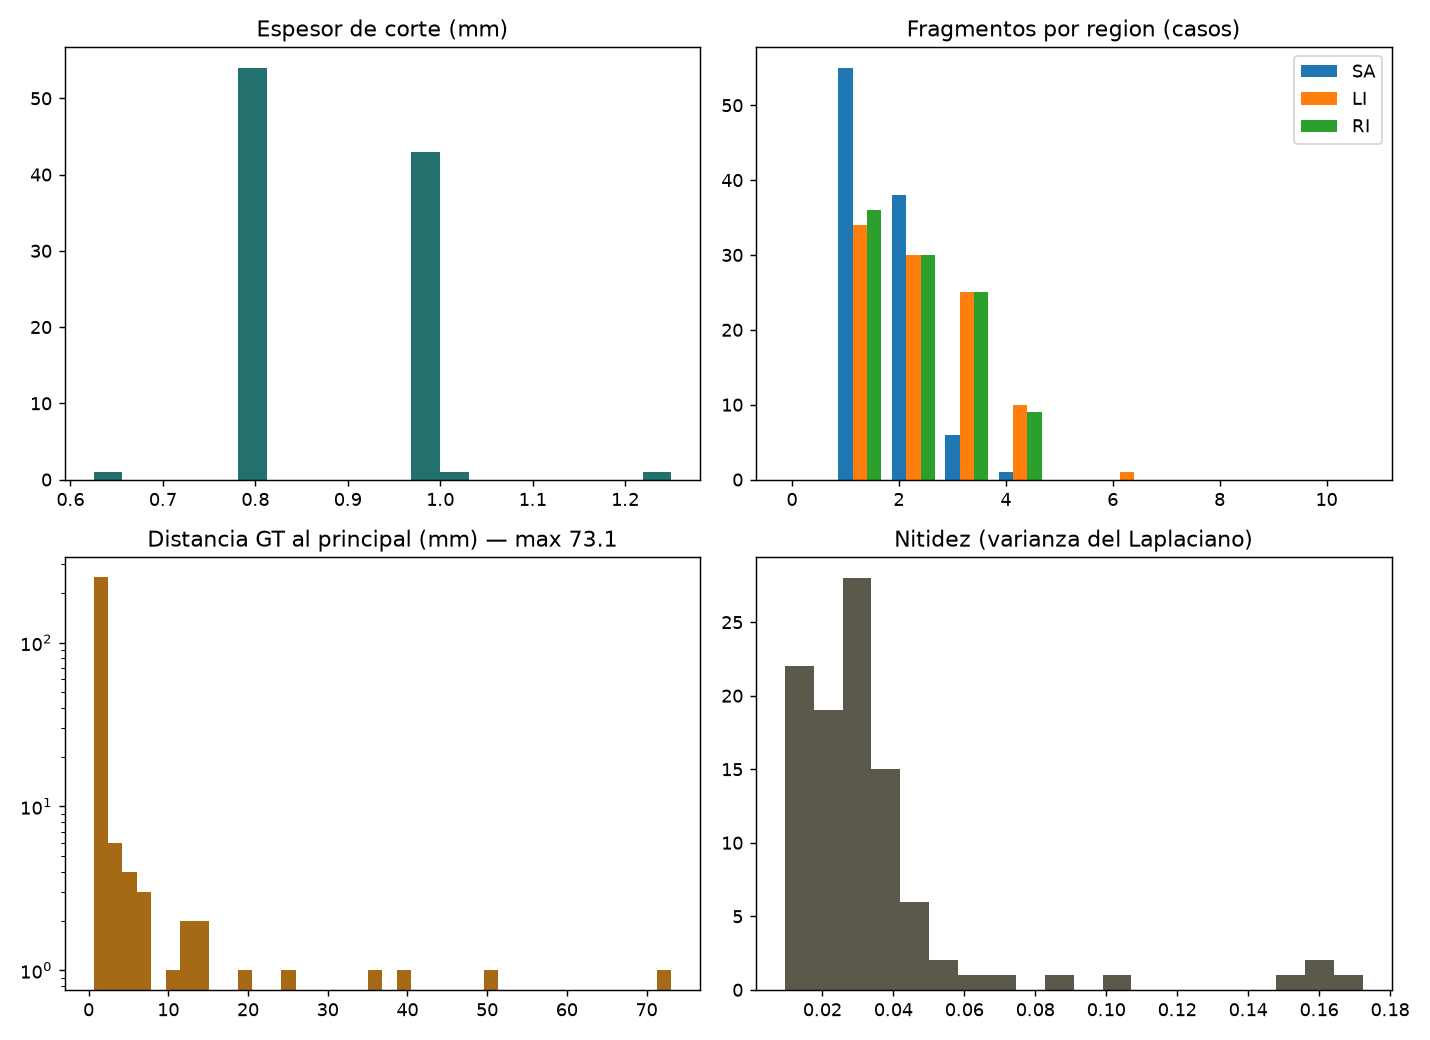

In [9]:
import pandas as pd
from IPython.display import Image, display

eda_casos = pd.read_csv(RES / "eda" / "eda_casos.csv")
eda_frag  = pd.read_csv(RES / "eda" / "eda_fragmentos.csv")
display(eda_casos.head())
display(eda_casos.describe().T)
if (RES / "eda" / "eda_resumen.png").exists():
    display(Image(str(RES / "eda" / "eda_resumen.png")))

**Qué revisar aquí antes de entrenar**:
- etiquetas dentro de 0..30 (el script avisa si no);
- rango de distancias GT → confirma el 2 mm–25 cm del profesor y justifica `log(1+d)`;
- percentiles de HU del hueso → ventana HU y umbral del MIP en `configs/default.yaml`;
- spacing en z → por qué toda distancia se mide en mm con el header.

In [10]:
from src.data.io import leer_volumen, listar_casos
from src.dashboard.visualizadores import vis_mip_raw
from src.analisis import cortes_con_fractura

fracturas = cortes_con_fractura(cfg["rutas"]["cache"], splits["splits"]["test"])
print("Pacientes de test (el modelo nunca los vio), ordenados por fragmentos secundarios:")
display(fracturas.head(8))

CASO = fracturas.loc[0, "caso"]   # el de más fragmentos; cambia el id para ver otro
casos = listar_casos(cfg["rutas"]["imagenes"], cfg["rutas"]["etiquetas"])
caso = next(c for c in casos if c["id"] == CASO)
hu, spacing, _ = leer_volumen(caso["imagen"])
gt, _, _ = leer_volumen(caso["etiqueta"])
print(f"caso {CASO} · forma {hu.shape} · spacing zyx {tuple(round(s, 3) for s in spacing)} mm")

# Visualizador 1: MIP del hueso por umbral de HU (preprocesamiento clasico, sin modelo)
vis_mip_raw(hu, spacing, umbral_hu=cfg["datos"]["umbral_hueso_hu"], angulo=0).show()

Pacientes de test (el modelo nunca los vio), ordenados por fragmentos secundarios:


,caso,secundarios,regiones_fracturadas,cortes_con_fractura,area_max_px,z_cache,z_nativo
0,039,6,3,218,2447,71,124
1,085,5,3,238,2212,74,96
2,084,5,3,218,1108,65,65
3,028,4,3,181,1697,57,94
4,004,3,3,141,1664,70,76
5,005,3,2,90,1624,54,143
6,002,3,2,113,1335,198,221
7,015,3,2,177,1242,164,168


caso 039 · forma (392, 154, 322) · spacing zyx (0.8, 1.22, 1.22) mm


## 3 · Antes de entrenar (semana 9)

**VRAM real.** Correrlo en la RTX 3050 (4 GB), el PC más limitado. Si un batch no cabe, se usa
uno menor y se sube `entrenamiento.acumulacion` en `default.yaml`.

In [11]:
PRUEBAS = RES / "pruebas"

def prueba(nombre, *args):
    """Muestra el resultado guardado de una prueba; solo la corre si no existe y CORRER_PRUEBAS = True."""
    ruta = PRUEBAS / f"{nombre}.txt"
    if ruta.exists() and not CORRER_PRUEBAS:
        print(f"Resultado guardado ({ruta}):\n")
        print(ruta.read_text(encoding="utf-8"))
    elif CORRER_PRUEBAS:
        correr(*args, guardar=ruta)
    else:
        print(f"Sin resultado guardado en {ruta} (CORRER_PRUEBAS = True para correrla)")

if torch.cuda.is_available() or (PRUEBAS / "perfil_memoria.txt").exists():
    prueba("perfil_memoria", "scripts/perfil_memoria.py", "--config", CONFIG)
else:
    print("(sin GPU: el perfil de memoria solo tiene sentido en GPU)")

Resultado guardado (resultados\pruebas\perfil_memoria.txt):

parametros: 6,791,354
GPU: NVIDIA GeForce RTX 3060 Laptop GPU (6.0 GB)

  res  batch   pico GB  estado
  224      4      0.42  OK
  224      8      0.86  OK
  224     12      1.24  OK
  224     16      1.62  OK
  256      4      0.61  OK
  256      8      1.09  OK
  256     12      1.58  OK
  256     16      2.07  OK



**Overfit test** — prueba de correctitud exigida en la semana 9: sobre un lote pequeño la
pérdida debe caer >90 % y las cajas deben ajustarse. Si no pasa, hay un bug; no tiene sentido
entrenar completo.

In [12]:
prueba("overfit_test", "scripts/overfit_test.py", "--config", CONFIG, "--cabezas", "cls", "det", "seg", "dist",
       "--pasos", 300 if torch.cuda.is_available() else 120)

Resultado guardado (resultados\pruebas\overfit_test.txt):

paso    0  total 9.6141  cls 0.761  det_obj 1.128  det_box 0.912  sem 2.445  rol 2.493  borde 0.756  dist 1.174
paso   25  total 6.7417  cls 0.190  det_obj 0.987  det_box 0.723  sem 1.862  rol 1.908  borde 0.654  dist 0.042
paso   50  total 4.5581  cls 0.023  det_obj 0.255  det_box 0.510  sem 1.530  rol 1.485  borde 0.467  dist 0.022
paso   75  total 3.5503  cls 0.004  det_obj 0.203  det_box 0.360  sem 1.261  rol 1.186  borde 0.341  dist 0.010
paso  100  total 2.8924  cls 0.004  det_obj 0.138  det_box 0.304  sem 1.028  rol 0.996  borde 0.232  dist 0.007
paso  125  total 2.2330  cls 0.000  det_obj 0.084  det_box 0.253  sem 0.731  rol 0.824  borde 0.167  dist 0.007
paso  150  total 1.6885  cls 0.000  det_obj 0.060  det_box 0.204  sem 0.457  rol 0.701  borde 0.120  dist 0.005
paso  175  total 1.2153  cls 0.000  det_obj 0.045  det_box 0.121  sem 0.263  rol 0.619  borde 0.089  dist 0.004
paso  200  total 1.0718  cls 0.000  det_obj 0

**Calibración de λ.** Mide la magnitud de cada pérdida y de su gradiente sobre el backbone
compartido (mismo razonamiento del ejemplo de la Semana 6, donde la pérdida de clase dominaba
~45×). Con esa tabla se fijan los λ en `default.yaml` y se justifican en el informe.

In [13]:
prueba("calibrar_lambdas", "scripts/calibrar_lambdas.py", "--config", CONFIG,
       "--lotes", 20 if torch.cuda.is_available() else 4)

Resultado guardado (resultados\pruebas\calibrar_lambdas.txt):


termino      magnitud   ||grad||  grad/ref  lambda sugerido
cls            0.7372     1.5908      2.64             0.38
det_obj        1.1292     0.1953      0.32             3.09
det_box        0.8966     0.1010      0.17             5.96
sem            2.4495     0.6025      1.00             1.00
rol            2.5102     0.6832      1.13             0.88
borde          0.7510     0.3061      0.51             1.97
dist           0.9977     0.9679      1.61             0.62

referencia: lambda_sem = 1. Redondear y justificar en el informe; ajustar con validacion.



## 4 · Entrenamiento por etapas (semanas 9–10)

Curriculum: detección → +segmentación → +distancia (backbone congelado) → ajuste conjunto.
Cada etapa guarda **el mejor checkpoint por validación** (no el último) en `checkpoints/<NOMBRE_EXP>/`.

**Recomendado: entrenar desde la terminal**, no desde aquí. Si VS Code se cierra o el kernel se
reinicia, un entrenamiento lanzado desde el notebook se pierde. Por eso `ENTRENAR = False` por defecto,
y la celda se niega a correr si ya hay checkpoints con ese `NOMBRE_EXP`.

- Para una sola etapa: agrega `"--etapas", "deteccion"`.
- Para reanudar tras un corte de Colab: agrega `"--reanudar", ruta_del_checkpoint`.
- En Colab/Kaggle, copien `checkpoints/` a Drive al terminar: la sesión se borra.

In [14]:
etapas_cfg = [e["nombre"] for e in cfg["entrenamiento"]["etapas"]]
existentes = [CKPT_DIR / f"mejor_{e}.pth" for e in etapas_cfg if (CKPT_DIR / f"mejor_{e}.pth").exists()]

if existentes and not (MODO_PRUEBA and ENTRENAR):
    print(f"Entrenamiento ya realizado: se muestran los checkpoints de {CKPT_DIR} (no se vuelve a entrenar)\n")
    filas = []
    for ruta in existentes:
        ck = torch.load(ruta, map_location="cpu", weights_only=False)
        m = ck.get("metricas", {})
        filas.append({"etapa": ck["etapa"], "mejor época": ck["epoca"], "val_score": m.get("val_score"),
                      "F1 cls": m.get("val_f1_cls"), "mAP@0.5": m.get("val_map50"), "IoU cajas": m.get("val_iou_det"),
                      "Dice regiones": m.get("val_dice_sem"), "fecha": ck.get("fecha"),
                      "huella": (ck.get("huella_predicciones") or "")[:12]})
        del ck
    display(pd.DataFrame(filas).set_index("etapa").round(4))
elif ENTRENAR:
    args = ["scripts/train.py", "--config", CONFIG, "--nombre", NOMBRE_EXP]
    if DEVICE:
        args += ["--device", DEVICE]
    correr(*args)
else:
    print(f"No hay entrenamiento en {CKPT_DIR} (ENTRENAR = True para entrenar desde aquí)")

Entrenamiento ya realizado: se muestran los checkpoints de checkpoints\sin_cbam_384 (no se vuelve a entrenar)



,mejor época,val_score,F1 cls,mAP@0.5,IoU cajas,Dice regiones,fecha,huella
etapa,,,,,,,,
segmentacion,10,0.9551,0.9888,0.9057,0.8958,0.9709,2026-10-16 16:01,cb6709bf7964
conjunto,2,0.9555,0.9897,0.9058,0.8953,0.9712,2026-10-16 16:34,b9c8f109e598


,epocas,mejor_val_score,minutos
etapa,,,
segmentacion,12,0.9551,196.2867
conjunto,8,0.9555,66.4417


Tiempo total de entrenamiento: 4.4 h



,etapa,epoca,total,val_total,val_f1_cls,val_map50,val_iou_det,val_dice_sem,val_score,seg_epoca
0,segmentacion,0,1.2819,1.4766,0.9821,0.9031,0.8745,0.9637,0.9496,1809.2
1,segmentacion,1,1.0211,1.3778,0.9853,0.9052,0.8826,0.9661,0.9522,1796.0
2,segmentacion,2,0.9469,1.3686,0.9842,0.9043,0.8824,0.9684,0.9523,1795.0
3,segmentacion,3,0.8845,1.3268,0.9870,0.9055,0.8871,0.9693,0.9540,1793.3
4,segmentacion,4,0.8403,1.3189,0.9865,0.9053,0.8892,0.9695,0.9537,1274.1
5,segmentacion,5,0.8009,1.2844,0.9885,0.9055,0.8921,0.9697,0.9546,469.9
6,segmentacion,6,0.7703,1.3024,0.9844,0.9053,0.8927,0.9685,0.9528,475.3
7,segmentacion,7,0.7497,1.2636,0.9877,0.9056,0.8928,0.9699,0.9544,474.6
8,segmentacion,8,0.7268,1.2443,0.9875,0.9058,0.8947,0.9709,0.9548,474.1
9,segmentacion,9,0.7117,1.2547,0.9890,0.9059,0.8948,0.9704,0.9551,473.3


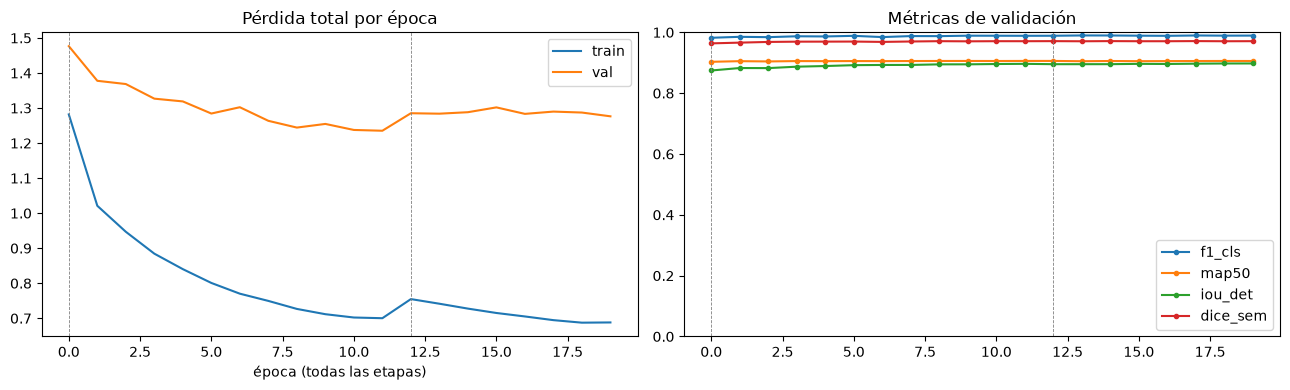

In [15]:
import matplotlib.pyplot as plt

ruta_log = RES / NOMBRE_EXP / "log_entrenamiento.csv"
if not ruta_log.exists():
    print(f"Todavia no hay log de entrenamiento en {ruta_log}")
else:
    log = pd.read_csv(ruta_log)
    resumen = log.groupby("etapa", sort=False).agg(epocas=("epoca", "count"), mejor_val_score=("val_score", "max"),
                                                    minutos=("seg_epoca", lambda x: x.sum() / 60))
    display(resumen.round(4))
    print(f"Tiempo total de entrenamiento: {log['seg_epoca'].sum() / 3600:.1f} h\n")
    pd.set_option("display.max_rows", 200)
    cols = ["etapa", "epoca", "total", "val_total", "val_f1_cls", "val_map50", "val_iou_det",
            "val_dice_sem", "val_score", "seg_epoca"]
    display(log[cols].round(4))
    log["paso"] = range(len(log))
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(log["paso"], log["total"], label="train")
    ax[0].plot(log["paso"], log["val_total"], label="val")
    ax[0].set_title("Pérdida total por época"); ax[0].set_xlabel("época (todas las etapas)"); ax[0].legend()
    for col in ["val_f1_cls", "val_map50", "val_iou_det", "val_dice_sem"]:
        if log[col].notna().any():
            ax[1].plot(log["paso"], log[col], marker=".", label=col.replace("val_", ""))
    ax[1].set_title("Métricas de validación"); ax[1].set_ylim(0, 1); ax[1].legend()
    for a in ax:
        for _, g in log.groupby("etapa", sort=False):
            a.axvline(g["paso"].iloc[0], color="gray", lw=0.6, ls="--")
    plt.tight_layout(); plt.show()

## 5 · Evaluación (semana 10)

Todas las métricas de la sección 5 (F1, AUC, IoU, mAP@0.50, mAP@[0.50:0.95], Dice e IoU de
fragmento) más HD95/ASSD, error de la distancia en mm contra el GT y latencia.
Niveles de degradación 0–3: evidencia de robustez a imágenes de baja calidad.

In [16]:
disponibles = sorted(CKPT_DIR.glob("mejor_*.pth"), key=lambda p: p.stat().st_mtime)
CKPT = CKPT_DIR / "mejor_conjunto.pth" if (CKPT_DIR / "mejor_conjunto.pth").exists() else (disponibles[-1] if disponibles else None)
print("checkpoint:", CKPT or f"ninguno en {CKPT_DIR}")

ev_guardadas = sorted((RES / NOMBRE_EXP).glob("evaluacion_*.json"))
if EVALUAR and CKPT:
    args = ["scripts/evaluar.py", "--config", CONFIG, "--ckpt", CKPT, "--nombre", NOMBRE_EXP,
            "--degradacion", 0, 1, 2, 3]
    if DEVICE:
        args += ["--device", DEVICE]
    correr(*args)
elif ev_guardadas:
    print("Evaluación ya realizada: se muestran los resultados guardados en la celda siguiente")
else:
    print("Todavía no hay evaluación (EVALUAR = True para correrla sobre test)")

checkpoint: checkpoints\sin_cbam_384\mejor_conjunto.pth
Evaluación ya realizada: se muestran los resultados guardados en la celda siguiente


In [17]:
dev_eval = DEVICE or ("cuda" if torch.cuda.is_available() else "cpu")
ruta_ev = RES / NOMBRE_EXP / f"evaluacion_{dev_eval}.json"
if not ruta_ev.exists():
    otras = sorted((RES / NOMBRE_EXP).glob("evaluacion_*.json"))
    ruta_ev = otras[0] if otras else ruta_ev
if not ruta_ev.exists():
    print(f"No hay evaluacion guardada en {ruta_ev}")
else:
    ev = json.load(open(ruta_ev))
    print(f"Evaluación: {ruta_ev.name} | checkpoint {Path(ev.get('ckpt', '')).name} | split {ev.get('split')}\n")
    filas = []
    for nivel, m in ev["por_nivel_degradacion"].items():
        fila = {"nivel": int(nivel)}
        for bloque in ("clasificacion", "deteccion", "segmentacion", "distancia"):
            for k, v in m.get(bloque, {}).items():
                if isinstance(v, (int, float)):
                    fila[k] = round(v, 3)
        fila["ms_por_corte"] = round(m.get("latencia_ms_por_corte", {}).get("media", float("nan")), 1)
        filas.append(fila)
    tabla_eval = pd.DataFrame(filas).set_index("nivel")
    display(tabla_eval.T)
    metas = {"f1_macro": .85, "auc_macro": .85, "iou_promedio": .65, "mAP@0.50": .65,
             "mAP@[0.50:0.95]": .40, "dice_fragmento": .85, "iou_fragmento": .70}
    print("Nivel 0 contra las metas del enunciado:")
    for k, meta in metas.items():
        v = tabla_eval.loc[0].get(k)
        print(f"  {k:18s} {v!s:>7}  meta >= {meta}  {'OK' if v is not None and v >= meta else '--'}")

Evaluación: evaluacion_cuda.json | checkpoint mejor_conjunto.pth | split test



nivel,0,1,2,3
f1_macro,0.981,0.979,0.983,0.978
auc_macro,0.999,0.999,0.998,0.997
iou_promedio,0.893,0.892,0.887,0.850
mAP@0.50,0.906,0.906,0.878,0.876
mAP@[0.50:0.95],0.767,0.765,0.755,0.690
dice_fragmento,0.700,0.694,0.669,0.614
iou_fragmento,0.628,0.622,0.589,0.522
hd95_mm,23.225,24.264,26.820,27.338
assd_mm,5.311,5.505,6.601,6.404
fragmentos_gt,91.000,91.000,91.000,91.000


Nivel 0 contra las metas del enunciado:
  f1_macro             0.981  meta >= 0.85  OK
  auc_macro            0.999  meta >= 0.85  OK
  iou_promedio         0.893  meta >= 0.65  OK
  mAP@0.50             0.906  meta >= 0.65  OK
  mAP@[0.50:0.95]      0.767  meta >= 0.4  OK
  dice_fragmento         0.7  meta >= 0.85  --
  iou_fragmento        0.628  meta >= 0.7  --


## 6 · Inferencia + visualizadores 2 y 3

Usa el checkpoint de la sección 5 sobre el paciente de test con más fragmentos (elegido en la
sección 2). El corte que se muestra es el de mayor área de fragmentos secundarios en el ground
truth, para que se vea la fractura. Debajo, ground truth contra predicción en ese mismo corte.

In [18]:
from src.inferencia import cargar_modelo, inferir_volumen
from src.dashboard.visualizadores import vis_corte, vis_reconstruccion
from src.utils import dispositivo

res = None
if CKPT is None:
    print("Sin checkpoint: se omite la inferencia")
else:
    dev = dispositivo(DEVICE)
    modelo = cargar_modelo(CKPT, cfg, dev)
    res = inferir_volumen(modelo, hu, spacing, cfg, dev)
    print(f"caso {CASO}: {len(res['tabla'])} fragmentos | {res['latencia']['ms_por_corte']:.1f} ms/corte en {dev}")
    if res["tabla"]:
        display(pd.DataFrame(res["tabla"])[["nombre", "es_principal", "volumen_ml", "distancia_mm", "distancia_cabeza_mm"]])

caso 039: 14 fragmentos | 23.3 ms/corte en cuda


,nombre,es_principal,volumen_ml,distancia_mm,distancia_cabeza_mm
0,SA-1,True,197.40,NaN,NaN
1,SA-2,False,1.50,0.8,1.64
2,SA-3,False,1.45,0.8,1.71
3,SA-4,False,1.18,0.8,1.58
4,SA-5,False,1.01,0.8,2.82
5,LI-1,True,276.17,NaN,NaN
6,LI-2,False,5.23,0.8,29.15
7,LI-3,False,3.77,0.8,10.48
8,LI-4,False,2.20,0.8,1.20
9,RI-1,True,280.08,NaN,NaN


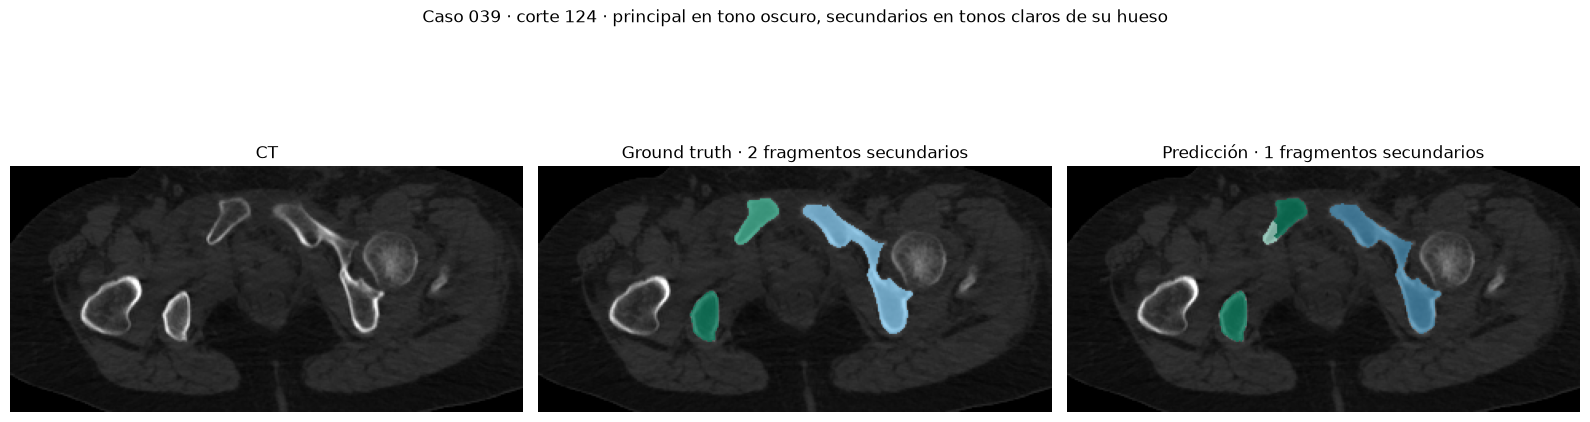

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from src.analisis import colorear_etiquetas
from src.data.etiquetas import COLORES_REGION, REGIONES, indice_en_region

if res is not None:
    etq = res["etiquetas"]
    area_sec = (indice_en_region(gt) >= 2).reshape(gt.shape[0], -1).sum(1)
    con_hueso = np.where(gt.reshape(gt.shape[0], -1).max(1) > 0)[0]
    Z = int(area_sec.argmax()) if area_sec.max() > 0 else int(con_hueso[len(con_hueso) // 2])
    vis_corte(hu[Z], etq[Z], res["detecciones"][Z], res["tabla"], cfg["datos"]["ventana_hu"],
              titulo=f"Predicción · corte {Z}").show()

    lo, hi = cfg["datos"]["ventana_hu"]
    fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
    for a, (titulo, capa) in zip(ax, [("CT", None), ("Ground truth", gt[Z]), ("Predicción", etq[Z])]):
        a.imshow(hu[Z], cmap="gray", vmin=lo, vmax=hi)
        if capa is not None:
            a.imshow(colorear_etiquetas(capa))
            n_sec = len([v for v in np.unique(capa) if v > 0 and indice_en_region(v) >= 2])
            titulo += f" · {n_sec} fragmentos secundarios"
        a.set_title(titulo)
        a.axis("off")
    plt.suptitle(f"Caso {CASO} · corte {Z} · principal en tono oscuro, secundarios en tonos claros de su hueso")
    plt.tight_layout()
    plt.show()

In [20]:
if res is not None and res["tabla"]:
    vis_reconstruccion(res["etiquetas"], spacing, res["tabla"]).show()
else:
    print("Sin fragmentos predichos: la reconstruccion 3D necesita un checkpoint con segmentacion")

## 7 · Interpretabilidad: qué aprendió y qué mira el modelo

Las métricas dicen cuánto acierta el modelo; esta sección muestra **por qué**. Cuatro análisis:

1. **γ de BatchNorm por bloque:** qué tanto usa la red cada capa.
2. **Grad-CAM contra objectness:** qué mira la red al decidir cada hueso (el mismo análisis del Taller 3).
3. **Cajas:** los candidatos de la cabeza de detección antes y después del NMS, y el IoU en todo test.
4. **Galería de fracturas:** ground truth contra predicción en los pacientes de test con más fragmentos.

### 7.1 γ de BatchNorm por bloque

Después de normalizar cada canal, BatchNorm lo escala y lo desplaza con dos parámetros aprendidos:
**y = γ · x̂ + β**. El γ dice cuánto deja pasar la red de ese canal a la capa siguiente:

- **γ ≈ 1** (su valor inicial): el canal se usa con normalidad.
- **γ → 0:** el canal está "apagado", casi no aporta y se podría podar (*Network Slimming*, Liu et al., 2017).
- **γ grande:** la red amplifica ese canal.

`pct_apagados` es el porcentaje de canales con |γ| menor al 5 % del máximo de su capa. Se calculan
para todos los modelos de la carpeta `pesos/` (el principal y las ablaciones), para compararlos.

In [21]:
from src.analisis import gammas_batchnorm, cargar_estado

PESOS = sorted(Path("pesos").glob("*.pth")) or ([CKPT] if CKPT else [])
gammas, crudos = {}, {}
for ruta in PESOS:
    gammas[ruta.stem], crudos[ruta.stem] = gammas_batchnorm(cargar_estado(ruta))
if not gammas:
    print("No hay pesos en pesos/ ni checkpoint")
for nombre, df in gammas.items():
    print(f"\nModelo: {nombre}")
    display(df.drop(columns=["modulo"]).set_index("capa").round(3))


Modelo: completo


,canales,gamma_medio_abs,gamma_mediana_abs,gamma_min_abs,gamma_max_abs,pct_apagados,beta_medio
capa,,,,,,,
Backbone · bloque 1,32,0.916,0.924,0.627,1.367,0.0,-0.018
Backbone · bloque 2,64,0.913,0.935,0.372,1.221,0.0,-0.238
Backbone · bloque 3,128,0.991,1.045,0.310,1.571,0.0,-0.326
Backbone · bloque 4,256,0.945,0.942,0.546,1.785,0.0,-0.289
Backbone · bloque 5,512,0.913,0.913,0.473,1.231,0.0,-0.215
Decoder · subida 1 · BN a,256,0.781,0.784,0.381,1.304,0.0,-0.368
Decoder · subida 1 · BN b,256,0.727,0.735,0.420,1.147,0.0,-0.323
Decoder · subida 2 · BN a,128,0.914,0.880,0.612,1.310,0.0,-0.280
Decoder · subida 2 · BN b,128,0.938,0.923,0.681,1.344,0.0,-0.265



Modelo: con_tl


,canales,gamma_medio_abs,gamma_mediana_abs,gamma_min_abs,gamma_max_abs,pct_apagados,beta_medio
capa,,,,,,,
Backbone · bloque 1,32,0.928,0.969,0.488,1.193,0.0,0.014
Backbone · bloque 2,64,0.920,0.965,0.498,1.178,0.0,-0.236
Backbone · bloque 3,128,1.007,1.036,0.441,1.505,0.0,-0.303
Backbone · bloque 4,256,0.933,0.942,0.510,1.722,0.0,-0.228
Backbone · bloque 5,512,0.901,0.900,0.632,1.148,0.0,-0.210
Decoder · subida 1 · BN a,256,0.759,0.731,0.403,1.231,0.0,-0.399
Decoder · subida 1 · BN b,256,0.701,0.693,0.399,1.062,0.0,-0.328
Decoder · subida 2 · BN a,128,0.902,0.869,0.560,1.326,0.0,-0.295
Decoder · subida 2 · BN b,128,0.906,0.908,0.597,1.345,0.0,-0.262



Modelo: mejorado_384


,canales,gamma_medio_abs,gamma_mediana_abs,gamma_min_abs,gamma_max_abs,pct_apagados,beta_medio
capa,,,,,,,
Backbone · bloque 1,32,0.920,0.925,0.619,1.360,0.0,-0.003
Backbone · bloque 2,64,0.913,0.923,0.387,1.200,0.0,-0.242
Backbone · bloque 3,128,0.989,1.033,0.330,1.576,0.0,-0.332
Backbone · bloque 4,256,0.944,0.943,0.562,1.849,0.0,-0.297
Backbone · bloque 5,512,0.909,0.915,0.451,1.262,0.0,-0.217
Decoder · subida 1 · BN a,256,0.784,0.789,0.370,1.286,0.0,-0.376
Decoder · subida 1 · BN b,256,0.738,0.744,0.405,1.146,0.0,-0.323
Decoder · subida 2 · BN a,128,0.917,0.895,0.648,1.313,0.0,-0.284
Decoder · subida 2 · BN b,128,0.949,0.926,0.693,1.406,0.0,-0.266



Modelo: sin_cbam


,canales,gamma_medio_abs,gamma_mediana_abs,gamma_min_abs,gamma_max_abs,pct_apagados,beta_medio
capa,,,,,,,
Backbone · bloque 1,32,0.879,0.909,0.555,1.351,0.0,0.063
Backbone · bloque 2,64,0.943,0.980,0.491,1.259,0.0,-0.240
Backbone · bloque 3,128,0.969,0.982,0.363,1.515,0.0,-0.358
Backbone · bloque 4,256,0.923,0.956,0.307,1.420,0.0,-0.409
Backbone · bloque 5,512,0.873,0.882,0.388,1.320,0.0,-0.332
Decoder · subida 1 · BN a,256,0.661,0.634,0.330,1.220,0.0,-0.490
Decoder · subida 1 · BN b,256,0.701,0.689,0.381,1.080,0.0,-0.394
Decoder · subida 2 · BN a,128,0.936,0.927,0.612,1.407,0.0,-0.288
Decoder · subida 2 · BN b,128,0.909,0.917,0.605,1.342,0.0,-0.278



Modelo: sin_cbam_384


,canales,gamma_medio_abs,gamma_mediana_abs,gamma_min_abs,gamma_max_abs,pct_apagados,beta_medio
capa,,,,,,,
Backbone · bloque 1,32,0.876,0.911,0.564,1.344,0.0,0.072
Backbone · bloque 2,64,0.943,0.977,0.479,1.251,0.0,-0.243
Backbone · bloque 3,128,0.968,0.982,0.374,1.508,0.0,-0.364
Backbone · bloque 4,256,0.917,0.961,0.344,1.380,0.0,-0.419
Backbone · bloque 5,512,0.868,0.876,0.381,1.319,0.0,-0.336
Decoder · subida 1 · BN a,256,0.657,0.620,0.329,1.228,0.0,-0.503
Decoder · subida 1 · BN b,256,0.716,0.707,0.392,1.065,0.0,-0.390
Decoder · subida 2 · BN a,128,0.941,0.933,0.633,1.418,0.0,-0.288
Decoder · subida 2 · BN b,128,0.920,0.912,0.626,1.369,0.0,-0.279


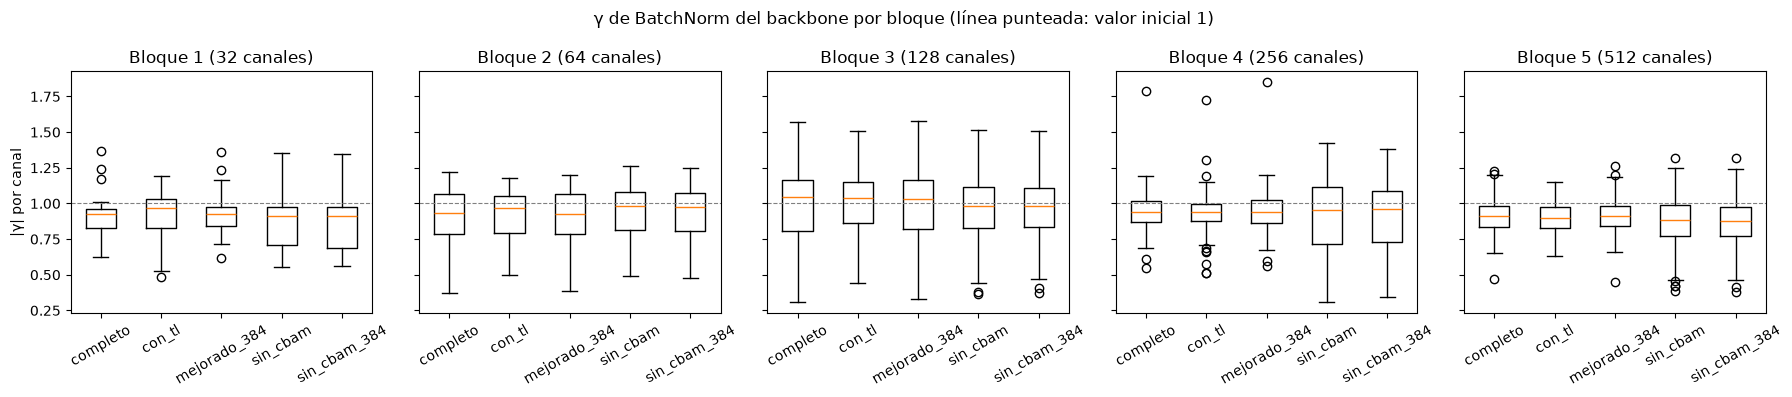

Comparación entre modelos:


completo                       con_tl  \
                          gamma_medio_abs pct_apagados gamma_medio_abs   
capa                                                                     
Backbone · bloque 1                 0.916          0.0           0.928   
Backbone · bloque 2                 0.913          0.0           0.920   
Backbone · bloque 3                 0.991          0.0           1.007   
Backbone · bloque 4                 0.945          0.0           0.933   
Backbone · bloque 5                 0.913          0.0           0.901   
Decoder · subida 1 · BN a           0.781          0.0           0.759   
Decoder · subida 1 · BN b           0.727          0.0           0.701   
Decoder · subida 2 · BN a           0.914          0.0           0.902   
Decoder · subida 2 · BN b           0.938          0.0           0.906   
Decoder · subida 3 · BN a           0.957          0.0           0.960   
Decoder · subida 3 · BN b           1.070          0.0           1.067   
Decoder · subida 4 · BN a           1.008          0.0           1.015   
Decoder · subida 4 · BN b           1.730          0.0           1.721   

                                          mejorado_384               \
                          pct_apagados gamma_medio_abs pct_apagados   
capa                                                                  
Backbone · bloque 1                0.0           0.920          0.0   
Backbone · bloque 2                0.0           0.913          0.0   
Backbone · bloque 3                0.0           0.989          0.0   
Backbone · bloque 4                0.0           0.944          0.0   
Backbone · bloque 5                0.0           0.909          0.0   
Decoder · subida 1 · BN a          0.0           0.784          0.0   
Decoder · subida 1 · BN b          0.0           0.738          0.0   
Decoder · subida 2 · BN a          0.0           0.917          0.0   
Decoder · subida 2 · BN b          0.0           0.949          0.0   
Decoder · subida 3 · BN a          0.0           0.957          0.0   
Decoder · subida 3 · BN b          0.0           1.088          0.0   
Decoder · subida 4 · BN a          0.0           1.008          0.0   
Decoder · subida 4 · BN b          0.0           1.716          0.0   

                                 sin_cbam                 sin_cbam_384  \
                          gamma_medio_abs pct_apagados gamma_medio_abs   
capa                                                                     
Backbone · bloque 1                 0.879          0.0           0.876   
Backbone · bloque 2                 0.943          0.0           0.943   
Backbone · bloque 3                 0.969          0.0           0.968   
Backbone · bloque 4                 0.923          0.0           0.917   
Backbone · bloque 5                 0.873          0.0           0.868   
Decoder · subida 1 · BN a           0.661          0.0           0.657   
Decoder · subida 1 · BN b           0.701          0.0           0.716   
Decoder · subida 2 · BN a           0.936          0.0           0.941   
Decoder · subida 2 · BN b           0.909          0.0           0.920   
Decoder · subida 3 · BN a           1.001          0.0           1.002   
Decoder · subida 3 · BN b           1.091          0.0           1.111   
Decoder · subida 4 · BN a           1.007          0.0           1.006   
Decoder · subida 4 · BN b           1.716          0.0           1.683   

                                        
                          pct_apagados  
capa                                    
Backbone · bloque 1                0.0  
Backbone · bloque 2                0.0  
Backbone · bloque 3                0.0  
Backbone · bloque 4                0.0  
Backbone · bloque 5                0.0  
Decoder · subida 1 · BN a          0.0  
Decoder · subida 1 · BN b          0.0  
Decoder · subida 2 · BN a          0.0  
Decoder · subida 2 · BN b          0.0  
Decoder · subida 3 · BN a         

In [22]:
if gammas:
    bloques = [c for c in next(iter(crudos.values())) if c.startswith("Backbone")]
    fig, axes = plt.subplots(1, len(bloques), figsize=(3.6 * len(bloques), 4), sharey=True)
    for a, b in zip(np.atleast_1d(axes), bloques):
        modelos = [m for m in crudos if b in crudos[m]]
        a.boxplot([np.abs(crudos[m][b]) for m in modelos], tick_labels=modelos)
        a.axhline(1.0, color="gray", lw=0.8, ls="--")
        a.set_title(f"{b.replace('Backbone · ', '').capitalize()} ({len(crudos[modelos[0]][b])} canales)")
        a.tick_params(axis="x", rotation=30)
    np.atleast_1d(axes)[0].set_ylabel("|γ| por canal")
    plt.suptitle("γ de BatchNorm del backbone por bloque (línea punteada: valor inicial 1)")
    plt.tight_layout()
    plt.show()

    if len(gammas) > 1:
        print("Comparación entre modelos:")
        comp = pd.concat({m: df.set_index("capa")[["gamma_medio_abs", "pct_apagados"]] for m, df in gammas.items()}, axis=1)
        display(comp.round(3))

**Cómo leerlo:** si ningún bloque tiene canales apagados, la red está usando toda su capacidad (no
le sobran filtros). Un bloque con muchos canales apagados indicaría capacidad de sobra en esa
profundidad. Entre modelos: el de transfer learning arranca con los γ aprendidos en el Taller 3, y
el que no tiene CBAM muestra cómo se reparte el trabajo sin el módulo de atención.

### 7.2 Grad-CAM contra objectness

**Grad-CAM** pondera cada canal del último mapa del backbone por el gradiente de la decisión de la
cabeza de clasificación ("¿está este hueso en el corte?") y muestra dónde se concentra esa
evidencia. **Smooth Grad-CAM** promedia el mapa sobre 8 copias de la entrada con ruido, como en el
Taller 3. Se compara con el **mapa de objectness** de la cabeza de detección, que responde otra
pregunta: dónde está el objeto.

Métricas, en el corte y la región de cada fila:
- **correlación** entre los dos mapas;
- **masa en caja:** fracción de cada mapa que cae dentro de la caja real;
- **masa uniforme:** la que tendría un mapa plano (el área de la caja). Una masa por encima de esa
  referencia quiere decir que el mapa se concentra en el hueso.

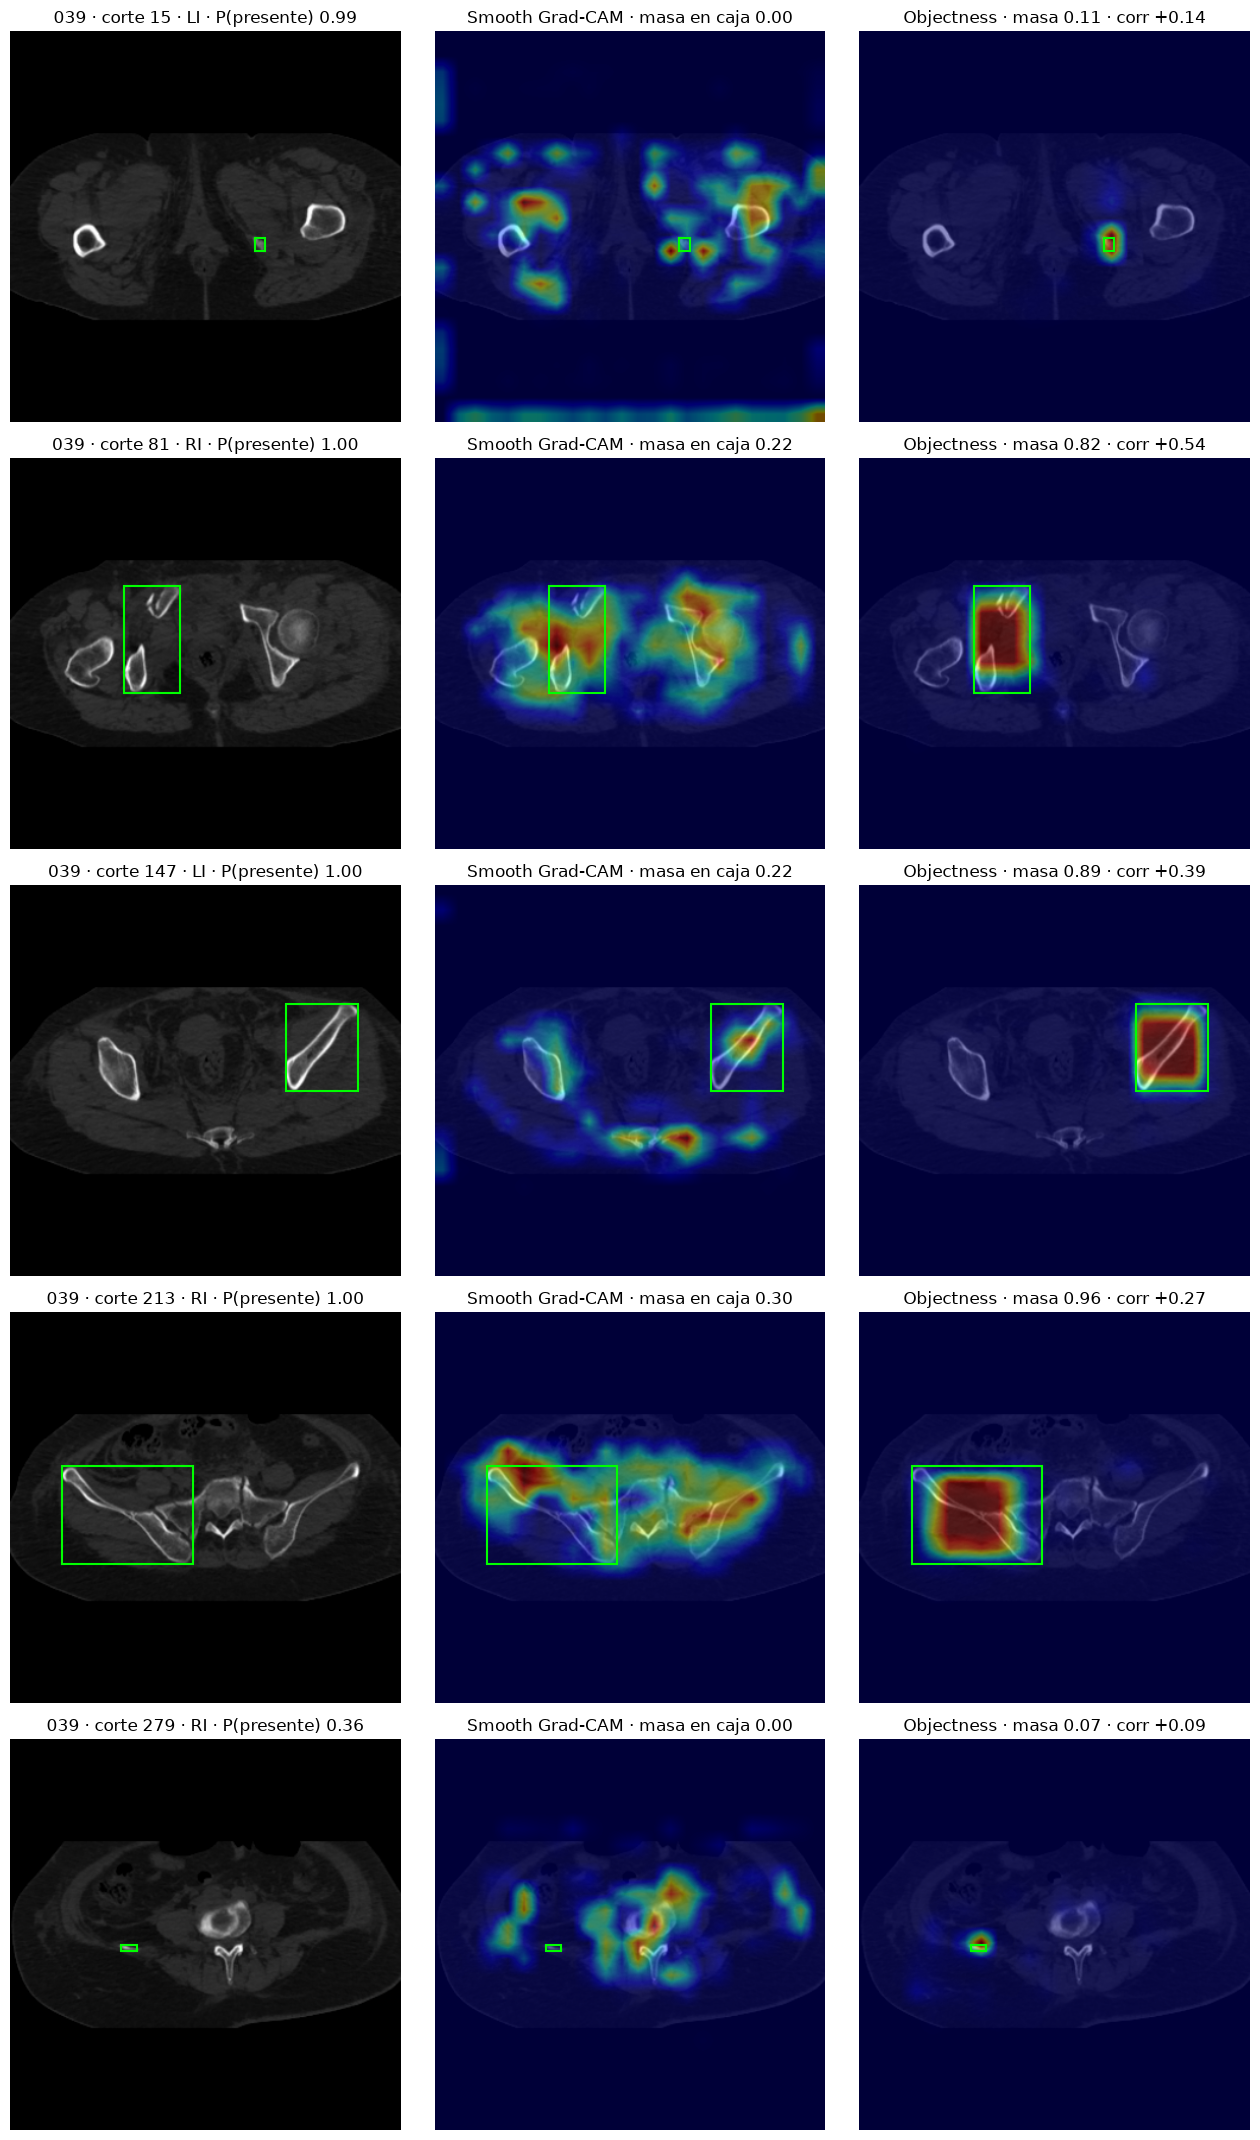

,corte,region,prob_cls,correlacion,masa_cam,masa_obj,masa_uniforme
0,15,LI,0.995,0.135,0.003,0.110,0.001
1,81,RI,1.000,0.536,0.218,0.822,0.039
2,147,LI,1.000,0.392,0.217,0.894,0.041
3,213,RI,1.000,0.270,0.301,0.958,0.083
4,279,RI,0.355,0.088,0.000,0.066,0.001


Promedios:
correlacion      0.284
masa_cam         0.148
masa_obj         0.570
masa_uniforme    0.033


In [23]:
from src.analisis import comparar_gradcam_objectness
from src.data.dataset import PengwinCortes

N_EJEMPLOS = 5
if CKPT is not None:
    ds_caso = PengwinCortes(cfg["rutas"]["cache"], [CASO], cfg)
    lbl_caso = np.load(Path(cfg["rutas"]["cache"]) / CASO / "lbl.npy", mmap_mode="r")
    tiene = np.asarray(lbl_caso).reshape(len(lbl_caso), -1).max(1) > 0
    candidatos = [i for i, (_, z) in enumerate(ds_caso.indice) if tiene[z]]
    elegidas = [ds_caso[candidatos[int(k)]] for k in np.linspace(0, len(candidatos) - 1, N_EJEMPLOS)]

    filas = []
    fig, axes = plt.subplots(len(elegidas), 3, figsize=(13, 4.3 * len(elegidas)))
    for fila_ax, m in zip(np.atleast_2d(axes), elegidas):
        areas = [float((m["cajas"][r, 2] - m["cajas"][r, 0]) * (m["cajas"][r, 3] - m["cajas"][r, 1]))
                 if m["hay_caja"][r] else -1.0 for r in range(3)]
        r = int(np.argmax(areas))
        caja = m["cajas"][r].tolist()
        gc = comparar_gradcam_objectness(modelo, m["img"], r, caja)
        base = m["img"][m["img"].shape[0] // 2].numpy()
        for a, mapa in zip(fila_ax, [None, gc["cam"], gc["obj"]]):
            a.imshow(base, cmap="gray")
            if mapa is not None:
                a.imshow(mapa, cmap="jet", alpha=0.45)
            x1, y1, x2, y2 = caja
            a.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="lime", lw=1.5))
            a.axis("off")
        fila_ax[0].set_title(f"{CASO} · corte {m['z']} · {REGIONES[r]} · P(presente) {gc['prob_cls']:.2f}")
        fila_ax[1].set_title(f"Smooth Grad-CAM · masa en caja {gc['masa_cam']:.2f}")
        fila_ax[2].set_title(f"Objectness · masa {gc['masa_obj']:.2f} · corr {gc['correlacion']:+.2f}")
        filas.append({"corte": m["z"], "region": REGIONES[r], "prob_cls": gc["prob_cls"],
                      "correlacion": gc["correlacion"], "masa_cam": gc["masa_cam"],
                      "masa_obj": gc["masa_obj"], "masa_uniforme": gc["masa_uniforme"]})
    plt.tight_layout()
    plt.show()

    tabla_gc = pd.DataFrame(filas)
    display(tabla_gc.round(3))
    print("Promedios:")
    print(tabla_gc[["correlacion", "masa_cam", "masa_obj", "masa_uniforme"]].mean().round(3).to_string())
else:
    print("Sin checkpoint: se omite")

### 7.3 Cajas: candidatos, NMS e IoU en test

La cabeza de detección propone una caja en cada celda del grid de 16 × 16 cuyo puntaje supera el
umbral (0.30). El NMS propio (`src/postprocess/nms.py`) conserva la mejor de cada región y descarta
las demás. Corte: el de más área de fragmentos del paciente elegido. Verde punteado = caja real.

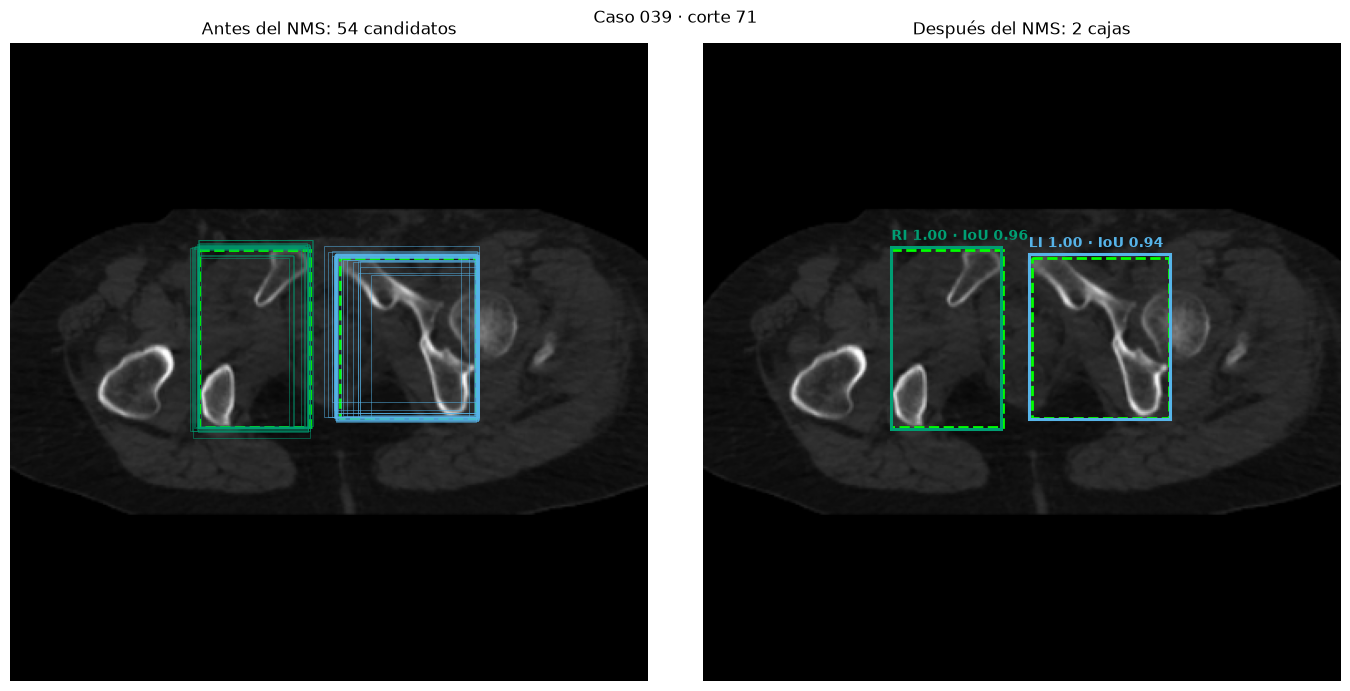

Probabilidad de presencia por región (cabeza de clasificación): {'SA': 0.077, 'LI': 1.0, 'RI': 1.0}


In [24]:
from src.analisis import cajas_de_corte, iou_caja

if CKPT is not None:
    z_c = int(fracturas.set_index("caso").loc[CASO, "z_cache"])
    m = ds_caso[next(i for i, (_, z) in enumerate(ds_caso.indice) if z == z_c)]
    cj = cajas_de_corte(modelo, m["img"], cfg)
    base = m["img"][m["img"].shape[0] // 2].numpy()
    fig, ax = plt.subplots(1, 2, figsize=(14, 7))
    paneles = [(f"Antes del NMS: {len(cj['candidatos'])} candidatos", cj["candidatos"], False),
               (f"Después del NMS: {len(cj['finales'])} cajas", cj["finales"], True)]
    for a, (titulo, cajas, final) in zip(ax, paneles):
        a.imshow(base, cmap="gray")
        a.set_title(titulo)
        a.axis("off")
        for r in range(3):
            if m["hay_caja"][r]:
                x1, y1, x2, y2 = m["cajas"][r].tolist()
                a.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="lime", lw=2, ls="--"))
        for d in cajas:
            col = np.array(COLORES_REGION[REGIONES[d["clase"]]]) / 255
            x1, y1, x2, y2 = d["caja"]
            a.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=col,
                                      lw=2.2 if final else 0.6, alpha=1 if final else 0.6))
            if final:
                txt = f"{REGIONES[d['clase']]} {d['score']:.2f}"
                if m["hay_caja"][d["clase"]]:
                    txt += f" · IoU {iou_caja(d['caja'], m['cajas'][d['clase']].tolist()):.2f}"
                a.text(x1, y1 - 4, txt, color=col, fontsize=10, weight="bold")
    plt.suptitle(f"Caso {CASO} · corte {m['z']}")
    plt.tight_layout()
    plt.show()
    print("Probabilidad de presencia por región (cabeza de clasificación):",
          {r: round(float(p), 3) for r, p in zip(REGIONES, cj["presencia"])})

**IoU en todo test:** la caja final de cada región contra la real, en 1 de cada 2 cortes de los 15
pacientes. Una región presente que no se detecta cuenta con IoU 0. Con GPU tarda 1–2 minutos.

,cortes,iou_medio,iou_mediana,pct_iou_mayor_05,pct_detectada,falsos_positivos
region,,,,,,
LI,1707,0.925,0.952,98.711,99.590,8
RI,1703,0.931,0.952,98.767,99.824,5
SA,1169,0.786,0.870,90.419,96.664,17


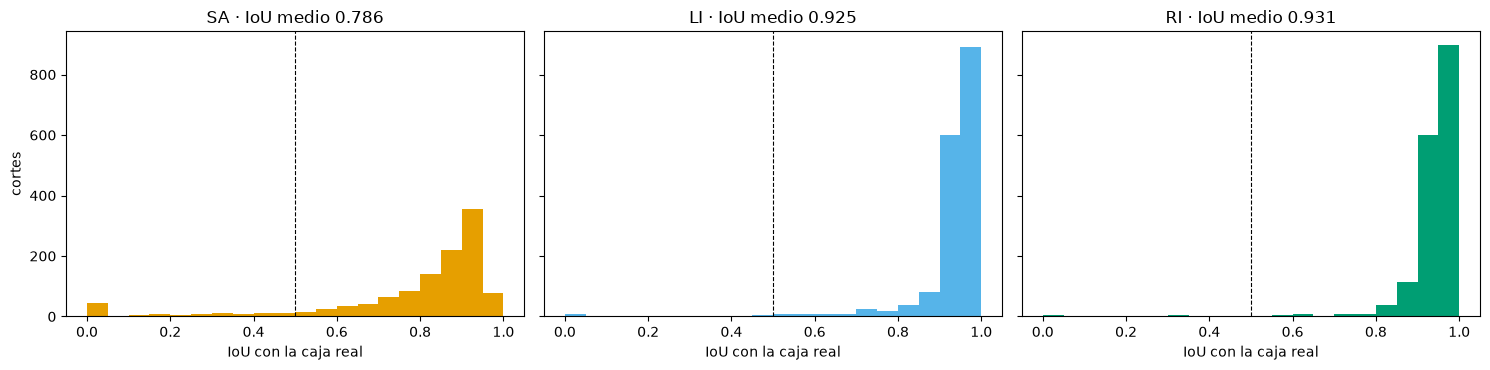

In [25]:
CALCULAR_IOU_TEST = True
if CALCULAR_IOU_TEST and CKPT is not None:
    from src.analisis import iou_cajas_en_test

    ds_test = PengwinCortes(cfg["rutas"]["cache"], splits["splits"]["test"], cfg)
    ious = iou_cajas_en_test(modelo, ds_test, cfg, cada=2)
    (RES / NOMBRE_EXP / "analisis").mkdir(parents=True, exist_ok=True)
    ious.to_csv(RES / NOMBRE_EXP / "analisis" / "iou_cajas_test.csv", index=False)

    en_gt = ious[ious["en_gt"]]
    resumen = en_gt.groupby("region").agg(cortes=("iou", "size"), iou_medio=("iou", "mean"),
                                          iou_mediana=("iou", "median"),
                                          pct_iou_mayor_05=("iou", lambda s: 100 * (s >= 0.5).mean()),
                                          pct_detectada=("detectada", lambda s: 100 * s.mean()))
    resumen["falsos_positivos"] = ious[~ious["en_gt"]].groupby("region").size().reindex(resumen.index).fillna(0).astype(int)
    display(resumen.round(3))

    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
    for a, r in zip(ax, REGIONES):
        v = en_gt[en_gt["region"] == r]["iou"]
        a.hist(v, bins=20, range=(0, 1), color=np.array(COLORES_REGION[r]) / 255)
        a.axvline(0.5, color="k", ls="--", lw=0.8)
        a.set_title(f"{r} · IoU medio {v.mean():.3f}")
        a.set_xlabel("IoU con la caja real")
    ax[0].set_ylabel("cortes")
    plt.tight_layout()
    plt.show()

### 7.4 Galería de fracturas

Los pacientes de test con más fragmentos secundarios: en cada uno, el corte con más área de
fragmentos, ground truth contra predicción. Cada caso corre la inferencia completa (unos segundos
por caso con GPU).

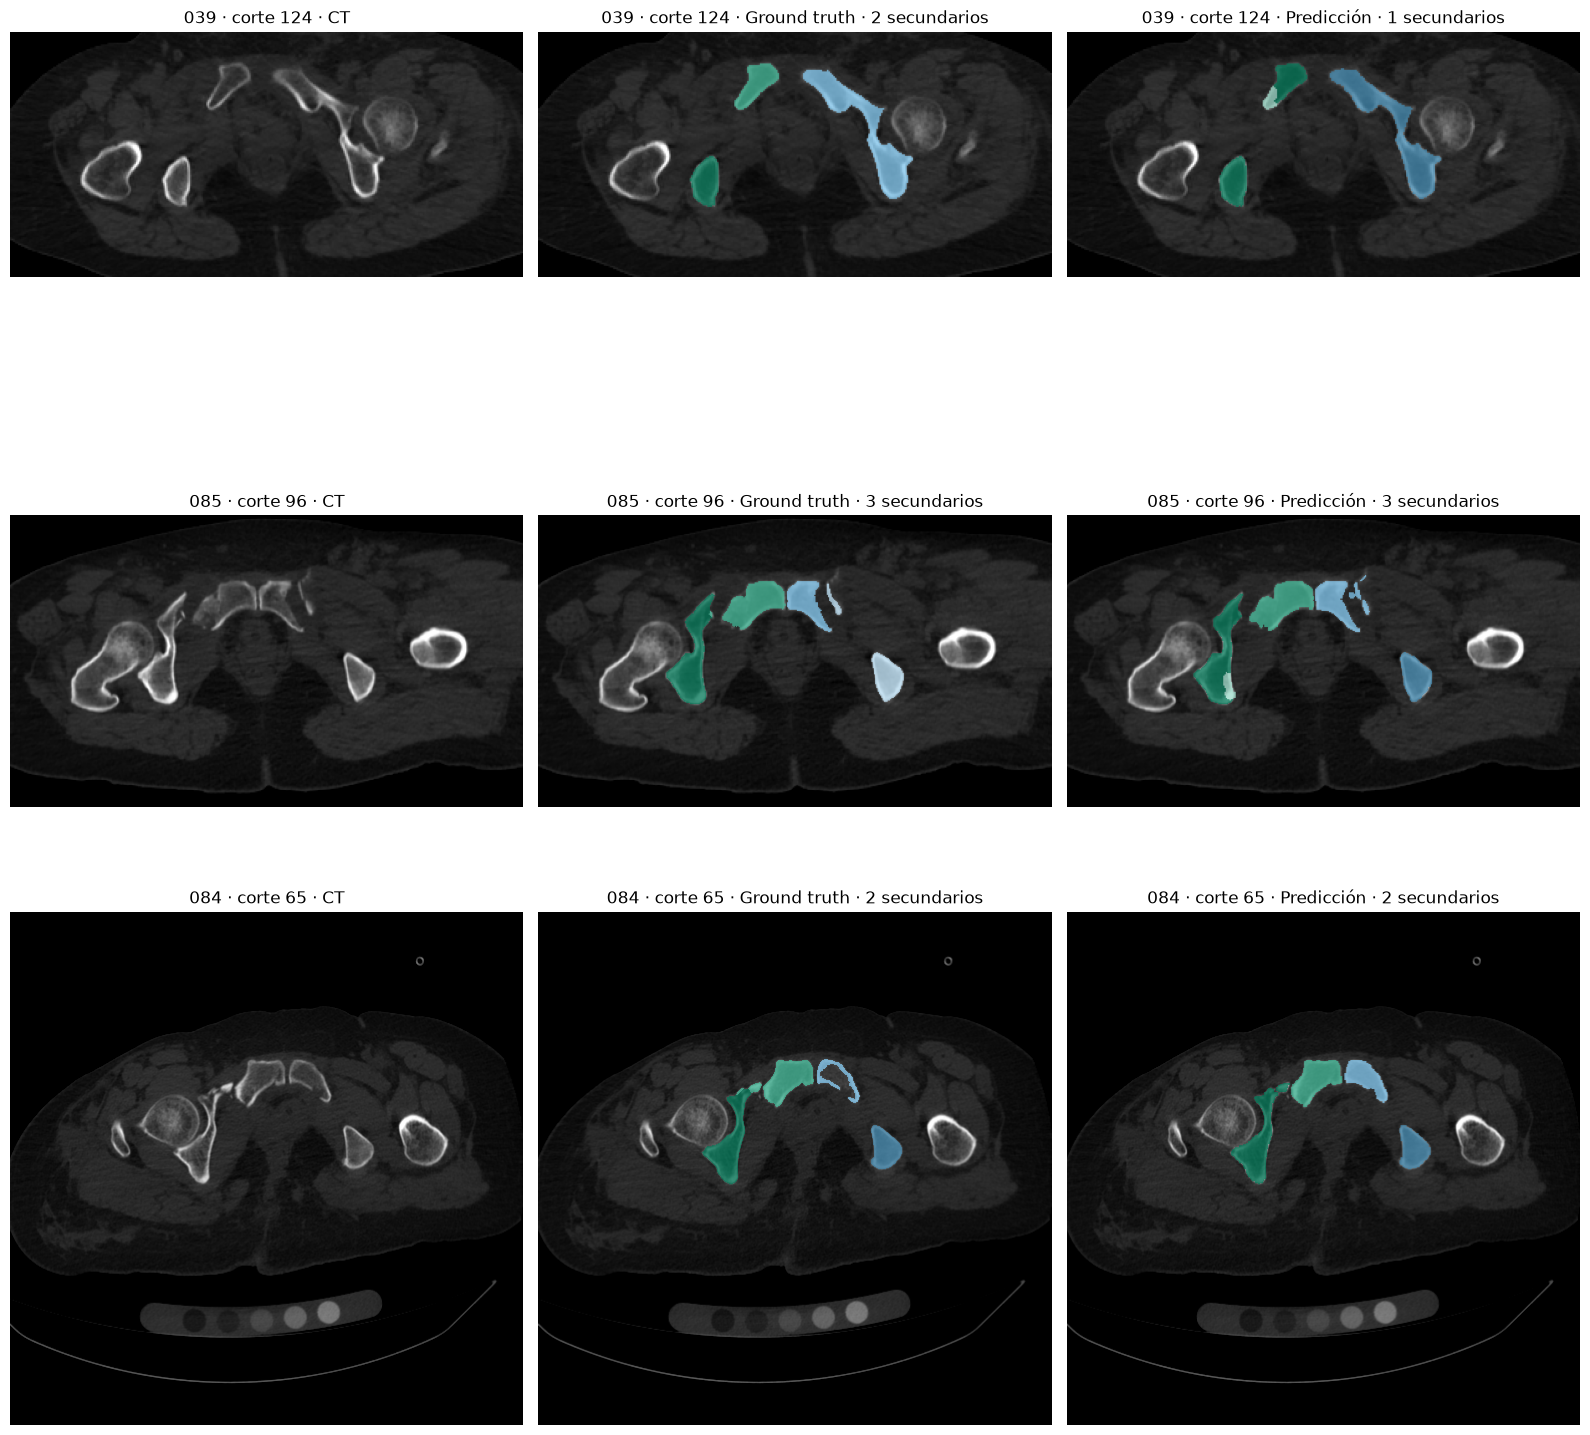

In [26]:
N_CASOS_FRACTURA = 3
if CKPT is not None:
    lo, hi = cfg["datos"]["ventana_hu"]
    n = min(N_CASOS_FRACTURA, len(fracturas))
    fig, axes = plt.subplots(n, 3, figsize=(16, 5.3 * n))
    for fila_ax, (_, f) in zip(np.atleast_2d(axes), fracturas.head(n).iterrows()):
        cs = next(c for c in casos if c["id"] == f["caso"])
        hu_c, sp_c, _ = leer_volumen(cs["imagen"])
        gt_c, _, _ = leer_volumen(cs["etiqueta"])
        pred_c = inferir_volumen(modelo, hu_c, sp_c, cfg, dev)["etiquetas"]
        z = int(f["z_nativo"])
        for a, (titulo, capa) in zip(fila_ax, [("CT", None), ("Ground truth", gt_c[z]), ("Predicción", pred_c[z])]):
            a.imshow(hu_c[z], cmap="gray", vmin=lo, vmax=hi)
            if capa is not None:
                a.imshow(colorear_etiquetas(capa))
                titulo += f" · {len([v for v in np.unique(capa) if v > 0 and indice_en_region(v) >= 2])} secundarios"
            a.set_title(f"{f['caso']} · corte {z} · {titulo}")
            a.axis("off")
        del hu_c, gt_c, pred_c
    plt.tight_layout()
    plt.show()

## 8 · Baseline SAM (semana 10)

SAM **solo** como referencia zero-shot: recibe como prompt la caja predicha por nuestro modelo
y se compara Dice/IoU contra el modelo propio. Descarga ~375 MB la primera vez.
Requiere `pip install git+https://github.com/facebookresearch/segment-anything.git`.

In [27]:
CORRER_SAM = False
if CORRER_SAM:
    import urllib.request
    sam_ckpt = Path("checkpoints/sam_vit_b_01ec64.pth")
    if not sam_ckpt.exists():
        urllib.request.urlretrieve("https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth", sam_ckpt)
    correr("scripts/baseline_sam.py", "--config", CONFIG, "--ckpt", CKPT, "--sam", sam_ckpt)

## 9 · Dashboard + túnel de Cloudflare (semana 11)

Streamlit bloquea la terminal, por eso se lanza en segundo plano. En local, lo más cómodo es
abrir dos terminales y correr:

```
streamlit run src/dashboard/app.py
cloudflared tunnel --url http://localhost:8501
```

El dashboard lee `configs/default.yaml`: para la demo real, las rutas de datos de ese archivo
deben apuntar al dataset. Cerrar el túnel en Windows: `taskkill /IM cloudflared.exe /F`.

In [28]:
LANZAR_DASHBOARD = False
if LANZAR_DASHBOARD:
    dash = subprocess.Popen([sys.executable, "-m", "streamlit", "run", "src/dashboard/app.py",
                             "--server.headless", "true"], cwd=RAIZ)
    print("dashboard en http://localhost:8501  (detener con: dash.terminate())")